
## Primer zadatka klasifikacije teksta

U fajlu “McDonald_s_Reviews.csv” su dati podaci o komentarima korisnika McDonalds
restorana o ovim restoranima, hrani, usluzi. Fajl sadrži sledeće kolone (varijable):

* **reviewer_id** - jedinstveni identifikator korisnika koji je ostavio komentar
* **store_address** - adresa restorana na koji se komentar odnosi
* **rating_count** - ukupan broj komentara za dati restoran
* **review** - tekst komentara korisnika
* **rating** - ocena koju je korisnik dao restoranu

Koristeći opisane podatke iz navedenog fajla, potrebno je uraditi sledeće:

Polazeći od kolone rating napraviti novu sentiment varijablu sa tri moguće vrednosti
(negativan, neutralan, pozitivan) primenjujući sledeće mapiranje:

* rating 1 i 2 se mapiraju u “negativan” sentiment,
* rating 3 se mapira u “neutralan” sentiment,
* rating 4 i 5 se mapiraju u “pozitivan” sentiment

Varijabla `sentiment` bi trebalo da posluži kao **_izlazna varijabla_** za klasifikaciju u ovom
zadatku.


Transformisati kolonu `review` u numerički oblik primenom `Vector Space Modela` i
konkretno, `TF-IDF` metrike za procenu značajnosti reči.

Takođe, proceniti da li bi još
neku od varijabli iz polaznog dataset-a trebalo primeniti za kreiranje modela i ako se
opredelite da neku / neke varijable uključite, obrazložite ukratko odluku.


Kreirati **prvi klasifikacioni model** primenom algoritma `Logističke regresije`, sa
podrazumevanim vrednostima hiperparametara.

Napraviti **predikcije** primenom kreiranog modela i izračunati **standardne evaluacione
metrike** (preciznost, odziv, F1) kako za svaku klasu pojedinačno, tako i sveukupno tj. na
nivou svih klasa. **Interpretirati** dobijene vrednosti metrika u kontekstu zadatka.

Kreirati **drugi klasifikacioni model** kroz postupak `podešavanja hiperparametara`.
U
komentaru navesti koje biste hiperparametre podešavali i na koji način tj. koristeći koje
opsege / liste vrednosti ako ne biste bili vremenski ograničeni. Zatim, izabrati dva
hiperparametra, jedan za transformaciju teksta, drugi za klasifikator, odnosno oba za
klasifikator ako hiperparametri nisu primenljivi za transformaciju teksta, i izvršite
podešavanje njihovih vrednosti kroz postupak (5-fold) kros-validacije.

Izvršiti **predikcije** primenom podešenog modela i izračunati standardne **evaluacione**
**metrike** (preciznost, odziv, F1) kako za svaku klasu pojedinačno, tako i sveukupno tj. na
nivou svih klasa.


**Uporediti** i prokomentarisati rezultate dobijene osnovnim i podešenim modelima.

In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
from IPython.display import display

from sentence_transformers import SentenceTransformer

import spacy

# SPACY_MODEL = 'en_core_web_sm' # or 'en_core_web_md'

In [2]:
RAND_STATE=1
SPACY_MODEL='en_core_web_sm'

### Ucitavanje i priprema podataka

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'McDonald_reviews_for_class.csv')
data.head()

,reviewer_id,store_address,rating_count,review,rating
0,4187,"724 Broadway, New York, NY 10003, United States",1.670,"They had a very limited space, but to make an ...",4
1,32761,"3501 Biscayne Blvd, Miami, FL 33137, United St...",2.810,clean restaurant customer service very good,5
2,12196,"1044 US-11, Champlain, NY 12919, United States",1.306,Fast and friendly service. Nice location.,5
3,12502,"501 W Imperial Hwy, Los Angeles, CA 90044, Uni...",2.722,Everytime I order from here something is alway...,1
4,3165,"429 7th Ave, New York, NY 10001, United States",2.052,Very fast and helpful oops and respectful,5


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    5000 non-null   int64  
 1   store_address  5000 non-null   str    
 2   rating_count   5000 non-null   float64
 3   review         4997 non-null   str    
 4   rating         5000 non-null   int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 195.4 KB


In [5]:
data.dropna(inplace=True)
data.reset_index(drop=True, inplace=True)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4997 entries, 0 to 4996
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    4997 non-null   int64  
 1   store_address  4997 non-null   str    
 2   rating_count   4997 non-null   float64
 3   review         4997 non-null   str    
 4   rating         4997 non-null   int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 195.3 KB


In [6]:
def get_sentiment(rating):
    if rating==3: return 'neutralan'
    return 'negativan' if rating < 3 else 'pozitivan'

In [7]:
data['sentiment'] = data.rating.apply(get_sentiment)
data.head(10)

,reviewer_id,store_address,rating_count,review,rating,sentiment
0,4187,"724 Broadway, New York, NY 10003, United States",1.670,"They had a very limited space, but to make an ...",4,pozitivan
1,32761,"3501 Biscayne Blvd, Miami, FL 33137, United St...",2.810,clean restaurant customer service very good,5,pozitivan
2,12196,"1044 US-11, Champlain, NY 12919, United States",1.306,Fast and friendly service. Nice location.,5,pozitivan
3,12502,"501 W Imperial Hwy, Los Angeles, CA 90044, Uni...",2.722,Everytime I order from here something is alway...,1,negativan
4,3165,"429 7th Ave, New York, NY 10001, United States",2.052,Very fast and helpful oops and respectful,5,pozitivan
5,25293,"7010 Bradlick Shopping Center, Annandale, VA 2...",595.000,Good,4,pozitivan
6,10169,"690 Alameda St, Los Angeles, CA 90021, United ...",2.614,Gave me an uncooked Mc chicken gave me food po...,1,negativan
7,16342,"10901 Riverside Dr, North Hollywood, CA 91602,...",1.795,Claims to be 24 hours but it������������������...,1,negativan
8,22248,2476 Kal���������������,2.175,The food was hot and just as I ordered it.\nRe...,5,pozitivan
9,24848,"9814 International Dr, Orlando, FL 32819, Unit...",5.466,"Friendly and fast service, but could use a lit...",3,neutralan


In [8]:
data.sentiment.value_counts(normalize=True)

sentiment
pozitivan    0.478287
negativan    0.370422
neutralan    0.151291
Name: proportion, dtype: float64

In [9]:
data.store_address.nunique()

37

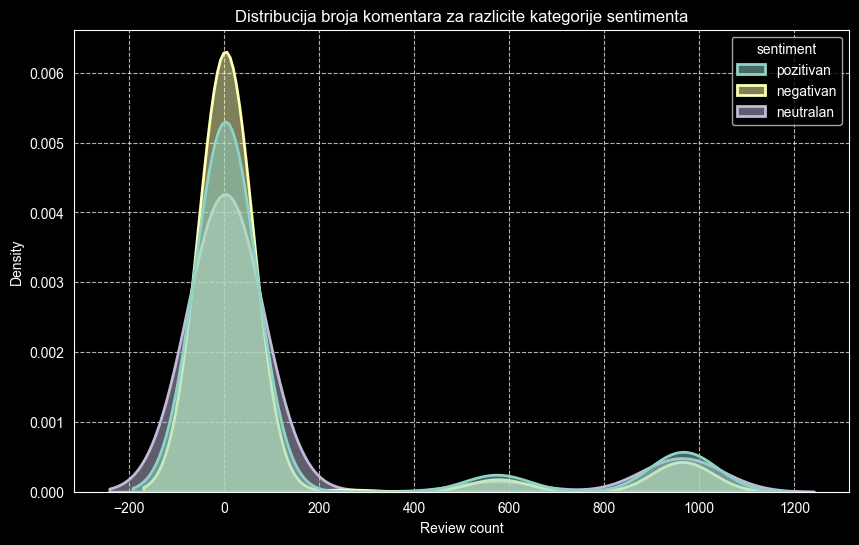

In [10]:
plt.figure(figsize=(10, 6))

sb.kdeplot(data=data,
           x='rating_count',
           hue='sentiment',
           fill=True,
           common_norm=False,
           alpha=0.5,
           linewidth=2)

plt.title('Distribucija broja komentara za razlicite kategorije sentimenta')
plt.xlabel('Review count')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [11]:
data.columns

Index(['reviewer_id', 'store_address', 'rating_count', 'review', 'rating',
       'sentiment'],
      dtype='str')

Varijabla `reviewer_id` predstavlja redni broj => ne zadrzavam je kao ulaznu varijablu.

Varijabla `store_address` ima cak 37 jedinstvenih vrednosti, sto je mnogo da bi se ukljucila kroz one-hot-encoding - nastalo bi puno novih binarnih varijabli. Mogla bi da se kreira nova varijabla ekstrakcijom grada iz adrese, ali ce fokus ostati na tekstu.

Varijabla `rating_count` ima slicnu raspodelu za sve tri klase sentimenta, tako da nije znacajna za kreiranje klasifikatora.

Varijabla `rating` se ne zadrzava zato sto je iskoriscena za kreiranje izlazne varijable `sentiment`.

**Kao ulazna varijabla zadrzava se samo `review`.**

### Transformacija teksta primenom Vector Space Modela

In [13]:
spacy_model = spacy.load(SPACY_MODEL, exclude=['parser', 'ner'])

In [14]:
def spacy_preprocessing(txt):
    tokens = spacy_model(txt)
    tokens = [token for token in tokens if
              (not token.is_punct) and
              (not token.is_space) and
              (not token.like_num) and
              (not token.like_url)]
    tokens = [token for token in tokens if
              (not token.is_stop) or token.lemma_.lower() == 'not']
    words = [token.lemma_.lower() for token in tokens]
    return words

In [15]:
tfidf_vectorizer = TfidfVectorizer(
    tokenizer=spacy_preprocessing,
    token_pattern=None,
    ngram_range=(1,2),
    min_df=0.01,
    max_df=0.95,
    norm='l1',
    smooth_idf=True
)

In [16]:
classifier = LogisticRegression(
    random_state=RAND_STATE,
    max_iter=2000
)

### Kreiranje i treniranje klasifikacionog pipeline-a

In [17]:
X = data['review']
y = data.sentiment.values

y_encodings, y_levels = pd.factorize(y)

X_train, X_test, y_train, y_test = train_test_split(X,
                                        y_encodings,
                                        test_size=0.2,
                                        random_state=RAND_STATE,
                                        stratify=y_encodings)

In [18]:
pipe = Pipeline([
    ('vectorizer', tfidf_vectorizer),
    ('classifier', classifier)
])

pipe.fit(X_train, y_train)

,steps,"[('vectorizer', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<function spa...0014E118DDBC0>


### Evaluacija modela na test podacima

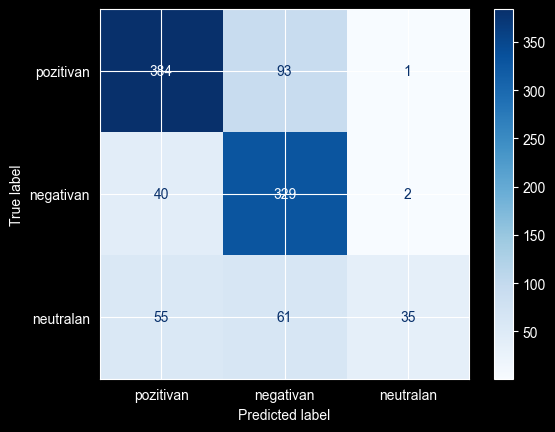

In [19]:
disp = ConfusionMatrixDisplay.from_estimator(estimator=pipe,
                                             X=X_test,
                                             y=y_test,
                                             display_labels=y_levels,
                                             cmap='Blues')

In [20]:
pred_1 = pipe.predict(X_test)
print(classification_report(y_true=y_test, y_pred=pred_1, target_names=y_levels))

              precision    recall  f1-score   support

   pozitivan       0.80      0.80      0.80       478
   negativan       0.68      0.89      0.77       371
   neutralan       0.92      0.23      0.37       151

    accuracy                           0.75      1000
   macro avg       0.80      0.64      0.65      1000
weighted avg       0.77      0.75      0.73      1000



### Interpretacija rezultata

Rezultati pokazuju zastupljenost klasa u datom skupu podataka.
Najvise zastupljena klasa je 'pozitivan' => ona ima najbolje rezultate.
Najmanje zastupljena - sa najslabijim rezultatima - je klasa 'neutralan'.

Klasa `POZITIVAN`

* precision 0.80 - od svih komentara za koje je predvidjeno da su pozitivnog sentimenta (384+40+55), 80% je stvarno pozitivno
* recall 0.80 - od svih komentara koji su stvarno pozitivnog sentimenta (384+93+1), 80% je klasifikovano kao pozitivno
* f1-score 0.80 - ukazuje na generalno dobru i balansiranu uspesnost modela u prepoznavanju pozitivnog sentimenta

Klasa `NEGATIVAN`

* precision 0.68 - od svih komentara za koje je predvidjeno da su negativnog sentimenta (93+329+61), 68% je stvarno negativno
* recall 0.89 - od svih komentara koji su stvarno negativnog sentimenta (40+329+2), 80% je klasifikovano kao negativno
* f1-score 0.77 - ukazuje na generalno dobru i balansiranu uspesnost modela u prepoznavanju negativnog sentimenta

Klasa `NEUTRALAN`

* precision 0.92 - od svih komentara za koje je predvidjeno da su neutralnog sentimenta (1+2+35), 92% je stvarno neutralno
* recall 0.23 - od svih komentara koji su stvarno neutralnog sentimenta (55+61+35), 23% je klasifikovano kao neutralno
* f1-score 0.37 - ukazuje na generalno vrlo slabu i nebalansiranu uspesnost modela u prepoznavanju neutralnog sentimenta

Na nivou svih klasa:
* `makro prosek (macro avg) F1 metrike` od 0.65 - slaba sposobnost modela da razlikuje sentiment komentara korisnika
* `otezani prosek (weighted avg) F1 metrike` od 0.73 - relativno dobra sposobnost modela da prepozna dominantan sentiment, posebno pozitivan sentiment

In [21]:
print(balanced_accuracy_score(y_true=y_test, y_pred=pred_1))

0.6406426042117052


#### Podesavanje hiperparametara

Hiperparametri koji se najcesce podesavaju pri radu sa TF-IDF vektorima tj. `TfIdfVectoriser` klasom su:
* `min_df` - min broj dokumenata u kojima je potrebno da se ngram pojavi da bi bio ukljucen u skup atributa
* `max_df` - max broj dokumenata u kojima ngram moze da se nadje da bi bio ukljucen u skup atributa
* `ngram_range` - ngrami koji ce biti razmotreni za kreiranje skupa atribita
* `max_features` - max broj atributa koji ce biti selektovani, nakon sortiranja po TF-IDF vrednosti

U slucaju klase `LogisticRegression`, postoji nekoliko znacajnih hiperparametara, medju kojima se posebno istice hiperaparametar **_C_** kojim se **_odredjuje intenzitet regularizacije modela_**
* male vrednosti za C vode jacoj regularizaciji i povecavaju sanse za underfitting
* vece vrednosti za C vode slabijoj regularizaciji i mogu da vode ka overfitting-u.

Opseg vrednosti za finetuning bi za svaki od navedenih hiperparametara bio:

* `min_df`: [0.001, 0.01, 0.05]
* `max_df`: [0.8, 0.9, 0.95]
* `ngram_range`: [(1,1), (1,2), (2,2)]
* `max_features`: [1000, 3000, 5000, 10000, 20000, None]
* `C`: [0.01, 0.1, 1, 10.0, 100.0]

U ovom zadatku cu za transformaciju teksta koristiti hiperparametar `min_df`, a za klasifikator `C`.

In [22]:
param_grid = {
    'vectorizer__min_df':[0.001, 0.05],
    'classifier__C':[0.1,1,10]
}

grid_search = GridSearchCV(estimator=pipe,
                           param_grid=param_grid,
                           scoring='f1_macro',
                           cv=5,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END ........classifier__C=0.1, vectorizer__min_df=0.001; total time=  13.4s
[CV] END ........classifier__C=0.1, vectorizer__min_df=0.001; total time=  13.5s
[CV] END ........classifier__C=0.1, vectorizer__min_df=0.001; total time=  19.1s
[CV] END ........classifier__C=0.1, vectorizer__min_df=0.001; total time=  20.7s
[CV] END ........classifier__C=0.1, vectorizer__min_df=0.001; total time=  19.1s
[CV] END .........classifier__C=0.1, vectorizer__min_df=0.05; total time=  19.4s
[CV] END .........classifier__C=0.1, vectorizer__min_df=0.05; total time=  19.3s
[CV] END .........classifier__C=0.1, vectorizer__min_df=0.05; total time=  19.0s
[CV] END .........classifier__C=0.1, vectorizer__min_df=0.05; total time=  19.0s
[CV] END .........classifier__C=0.1, vectorizer__min_df=0.05; total time=  19.0s
[CV] END ..........classifier__C=1, vectorizer__min_df=0.001; total time=  19.1s
[CV] END ..........classifier__C=1, vectorizer__m

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1, ...], 'vectorizer__min_df': [0.001, 0.05]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is al

In [23]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'classifier__C': 10, 'vectorizer__min_df': 0.001}
0.6834061224882391


In [24]:
best_min_df = grid_search.best_params_['vectorizer__min_df']
best_C = grid_search.best_params_['classifier__C']
pipe.set_params(vectorizer__min_df=best_min_df, classifier__C=best_C)
pipe.fit(X_train, y_train)

,steps,"[('vectorizer', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<function spa...0014E118DDBC0>


#### Predvidjanje i evaluacione metrike na podesenom modelu

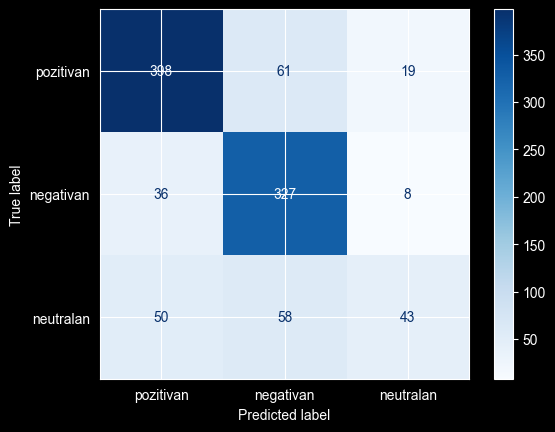

In [25]:
disp = ConfusionMatrixDisplay.from_estimator(estimator=pipe,
                                             X=X_test,
                                             y=y_test,
                                             display_labels=y_levels,
                                             cmap='Blues')

In [26]:
pred_2 = pipe.predict(X_test)
print(classification_report(y_true=y_test, y_pred=pred_2, target_names=y_levels))

              precision    recall  f1-score   support

   pozitivan       0.82      0.83      0.83       478
   negativan       0.73      0.88      0.80       371
   neutralan       0.61      0.28      0.39       151

    accuracy                           0.77      1000
   macro avg       0.72      0.67      0.67      1000
weighted avg       0.76      0.77      0.75      1000



In [27]:
print(balanced_accuracy_score(y_true=y_test, y_pred=pred_1))

0.6406426042117052


### Poredjenje kreiranih modela

In [28]:
def get_model_metrics(y_true:np.ndarray, y_pred:np.ndarray, model_name:str):

    # compute P, R, F1 for both averages
    report = classification_report(y_true, y_pred, output_dict=True)

    # compute balanced accuracy
    b_acc = balanced_accuracy_score(y_true, y_pred)

    # extract metrics for the specified averages
    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc
    }

    return results

In [29]:
models = {
    'TF-IDF_LR':pred_1,
    'TF-IDF_LR_FT':pred_2
}

results_list = list()

for model_name, pred in models.items():
    results_list.append(get_model_metrics(y_test, pred, model_name))

results_df = pd.DataFrame(results_list)
results_df.set_index('Model', inplace=True)
results_df = results_df.apply(lambda x: round(x,4))

print("Poredjenje uspesnosti modela:")
print(results_df)

Poredjenje uspesnosti modela:
              Macro Precision  Macro Recall  Macro F1-Score  \
Model                                                         
TF-IDF_LR              0.8013        0.6406          0.6478   
TF-IDF_LR_FT           0.7233        0.6663          0.6724   

              Weighted Precision  Weighted Recall  Weighted F1-Score  \
Model                                                                  
TF-IDF_LR                 0.7750            0.748             0.7254   
TF-IDF_LR_FT              0.7578            0.768             0.7513   

              Balanced Accuracy  
Model                            
TF-IDF_LR                0.6406  
TF-IDF_LR_FT             0.6663  


Model sa optimizovanim vrednostima hiperparametara ostvario je opste poboljsanje performansi u odnosu na polazni model, pri cemu je nakon optimizacije postao znatno balansiraniji i uspesniji u klasifikaciji.
